In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

In [2]:
iris = load_iris()

In [3]:
dir(iris)

['DESCR',
 'data',
 'data_module',
 'feature_names',
 'filename',
 'frame',
 'target',
 'target_names']

In [4]:
df = pd.DataFrame(iris.data,columns=iris['feature_names'])
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [5]:
df['Target'] =iris.target
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [6]:
df['flower_name'] = df['Target'].apply(lambda x: iris.target_names[x] )
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target,flower_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2,virginica
146,6.3,2.5,5.0,1.9,2,virginica
147,6.5,3.0,5.2,2.0,2,virginica
148,6.2,3.4,5.4,2.3,2,virginica


In [7]:
dfn = df[['petal length (cm)','petal width (cm)','Target']]
dfn

,petal length (cm),petal width (cm),Target
0,1.4,0.2,0
1,1.4,0.2,0
2,1.3,0.2,0
3,1.5,0.2,0
4,1.4,0.2,0
...,...,...,...
145,5.2,2.3,2
146,5.0,1.9,2
147,5.2,2.0,2
148,5.4,2.3,2


In [8]:
dfn0 = dfn[dfn['Target']==0]
dfn1 = dfn[dfn['Target']==1]
dfn2 = dfn[dfn['Target']==2]

Text(0, 0.5, 'Petal width (cm)')

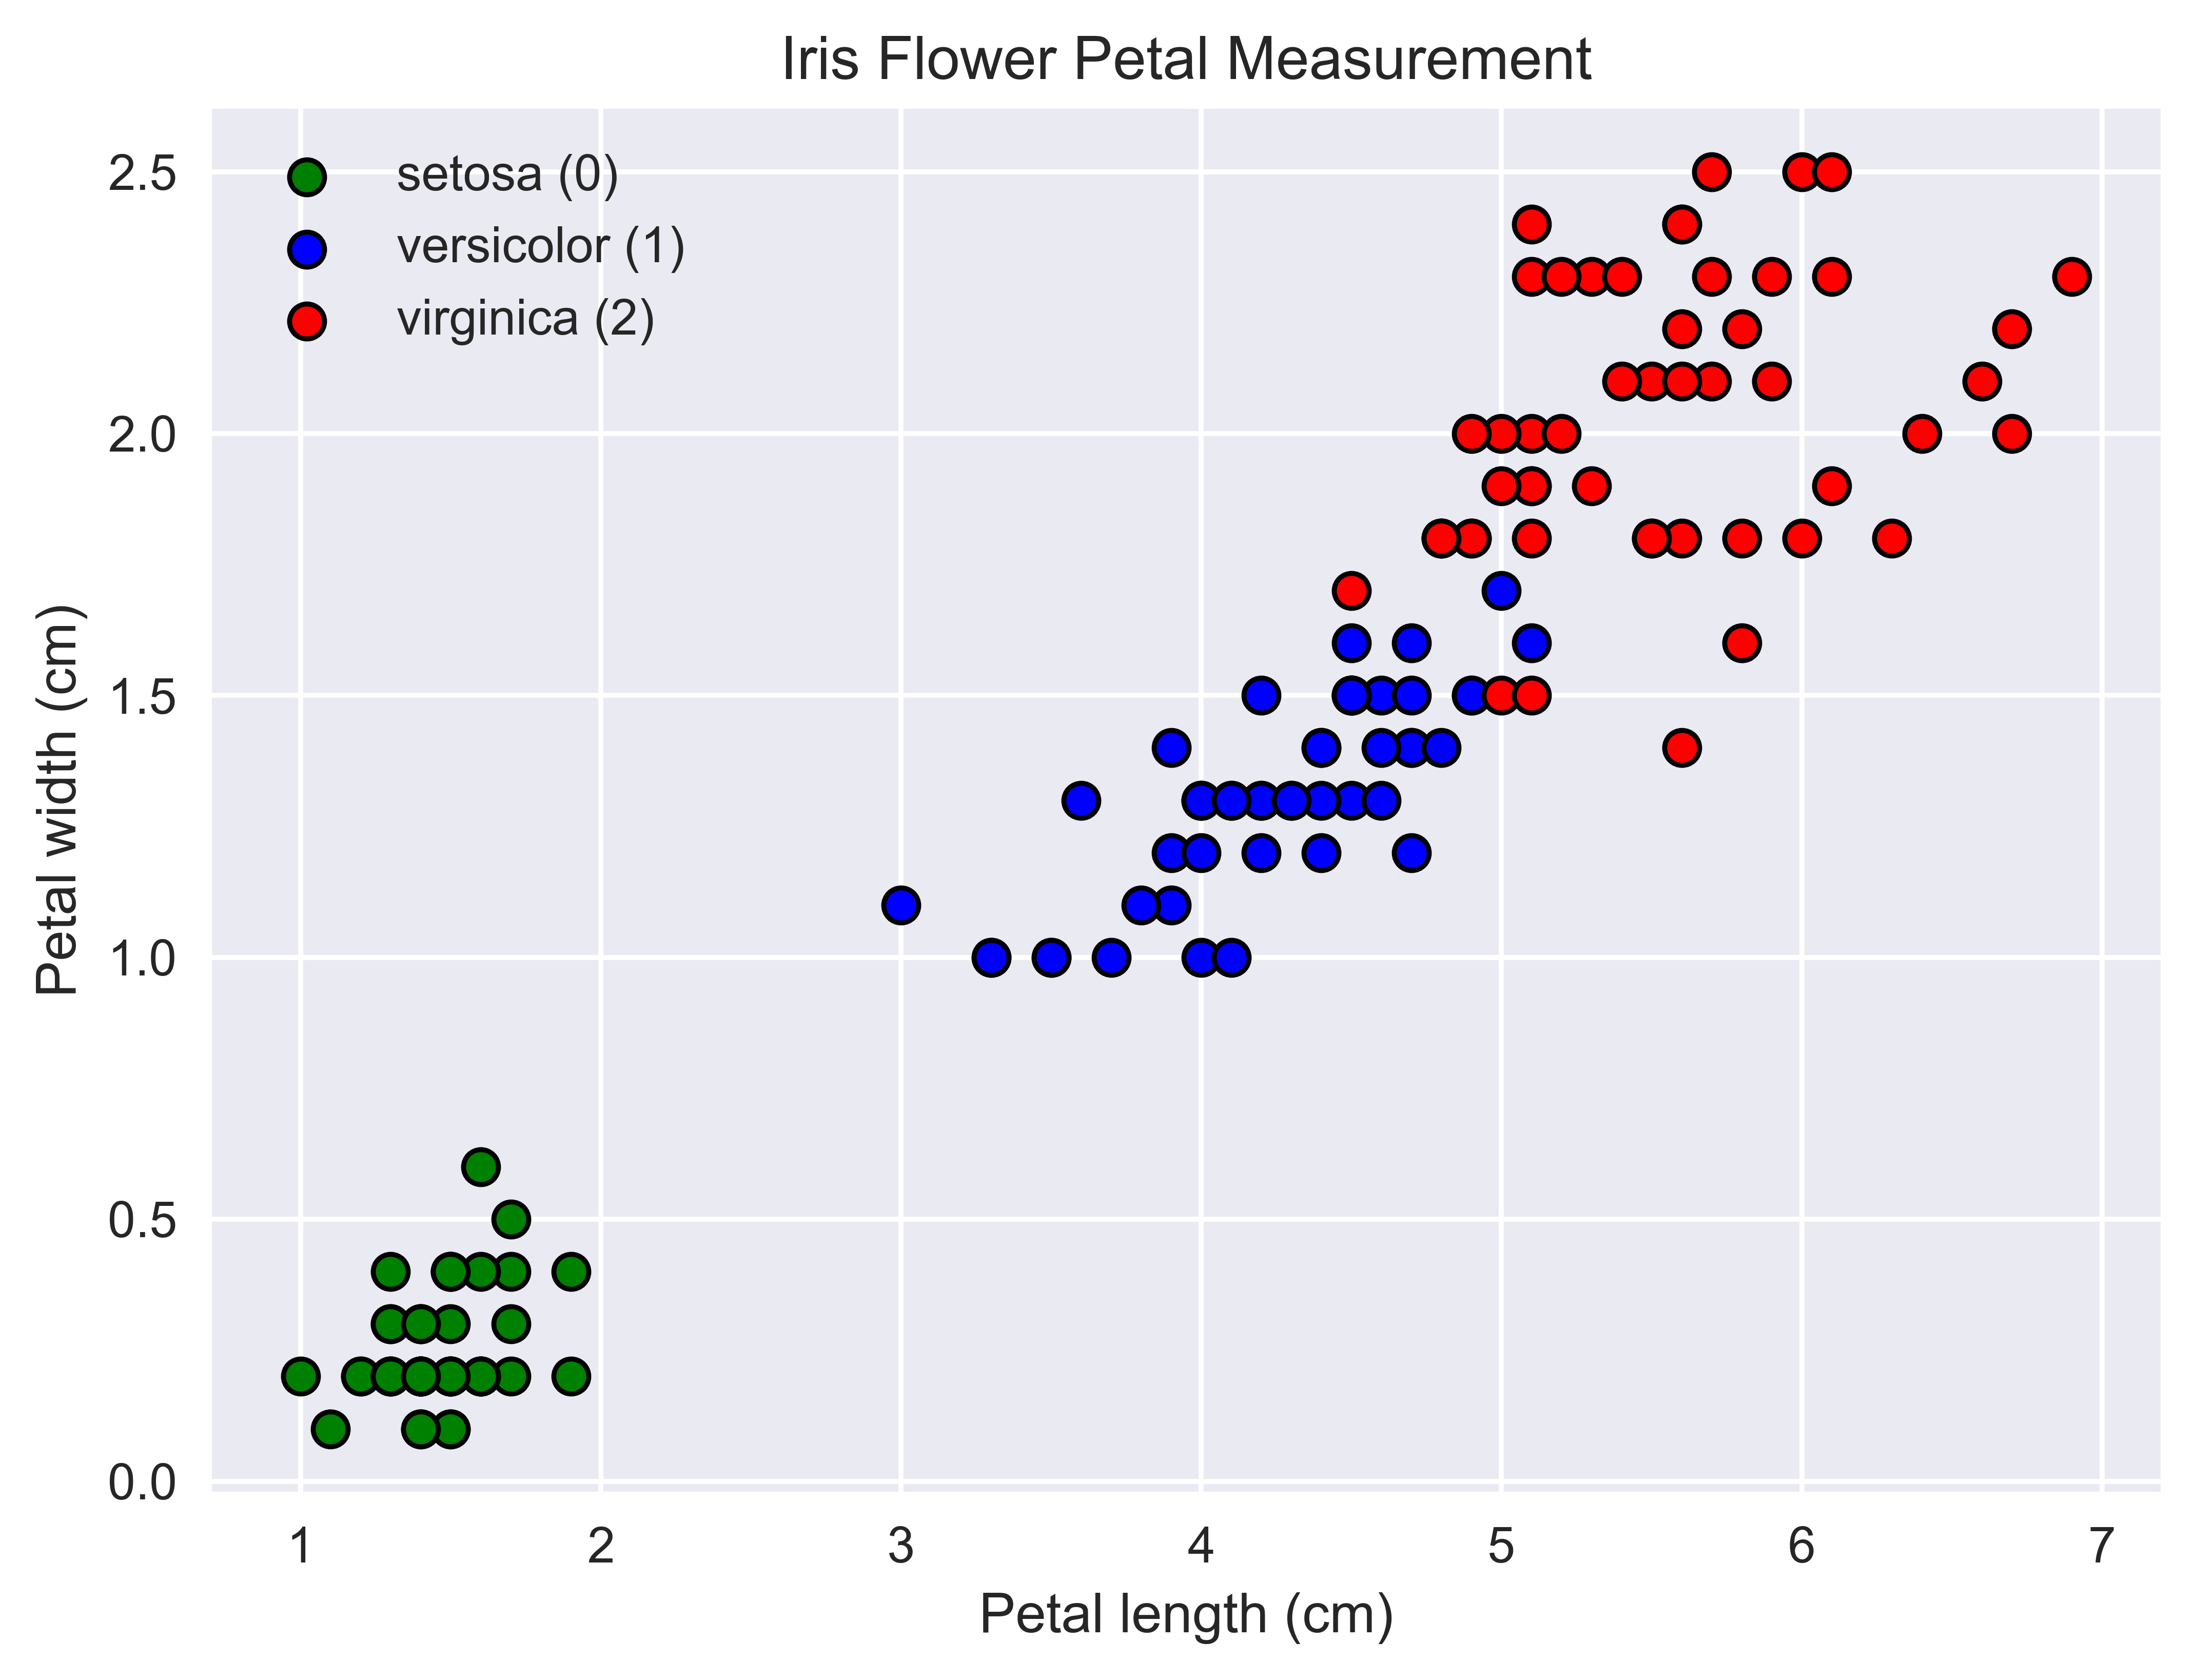

In [9]:
plt.figure(figsize=(7,5),dpi=700)
plt.style.use('seaborn')
plt.scatter(dfn0['petal length (cm)'],dfn0['petal width (cm)'],color='green',marker='o',edgecolor='black',linewidth=1,label='setosa (0)')
plt.scatter(dfn1['petal length (cm)'],dfn1['petal width (cm)'],color='blue',marker='o',edgecolor='black',linewidth=1,label='versicolor (1)')
plt.scatter(dfn2['petal length (cm)'],dfn2['petal width (cm)'],color='red',marker='o',edgecolor='black',linewidth=1,label='virginica (2)')
plt.legend()
plt.title('Iris Flower Petal Measurement')
plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')

In [10]:
dfn

,petal length (cm),petal width (cm),Target
0,1.4,0.2,0
1,1.4,0.2,0
2,1.3,0.2,0
3,1.5,0.2,0
4,1.4,0.2,0
...,...,...,...
145,5.2,2.3,2
146,5.0,1.9,2
147,5.2,2.0,2
148,5.4,2.3,2


In [11]:
scaler = MinMaxScaler()
scaler.fit(dfn[['petal length (cm)']])
dfn['petal length (cm)'] = scaler.transform(dfn[['petal length (cm)']])

scaler.fit(dfn[['petal width (cm)']])
dfn['petal width (cm)'] = scaler.transform(dfn[['petal width (cm)']])

dfn

,petal length (cm),petal width (cm),Target
0,0.067797,0.041667,0
1,0.067797,0.041667,0
2,0.050847,0.041667,0
3,0.084746,0.041667,0
4,0.067797,0.041667,0
...,...,...,...
145,0.711864,0.916667,2
146,0.677966,0.750000,2
147,0.711864,0.791667,2
148,0.745763,0.916667,2


Text(0, 0.5, 'Petal width (cm)')

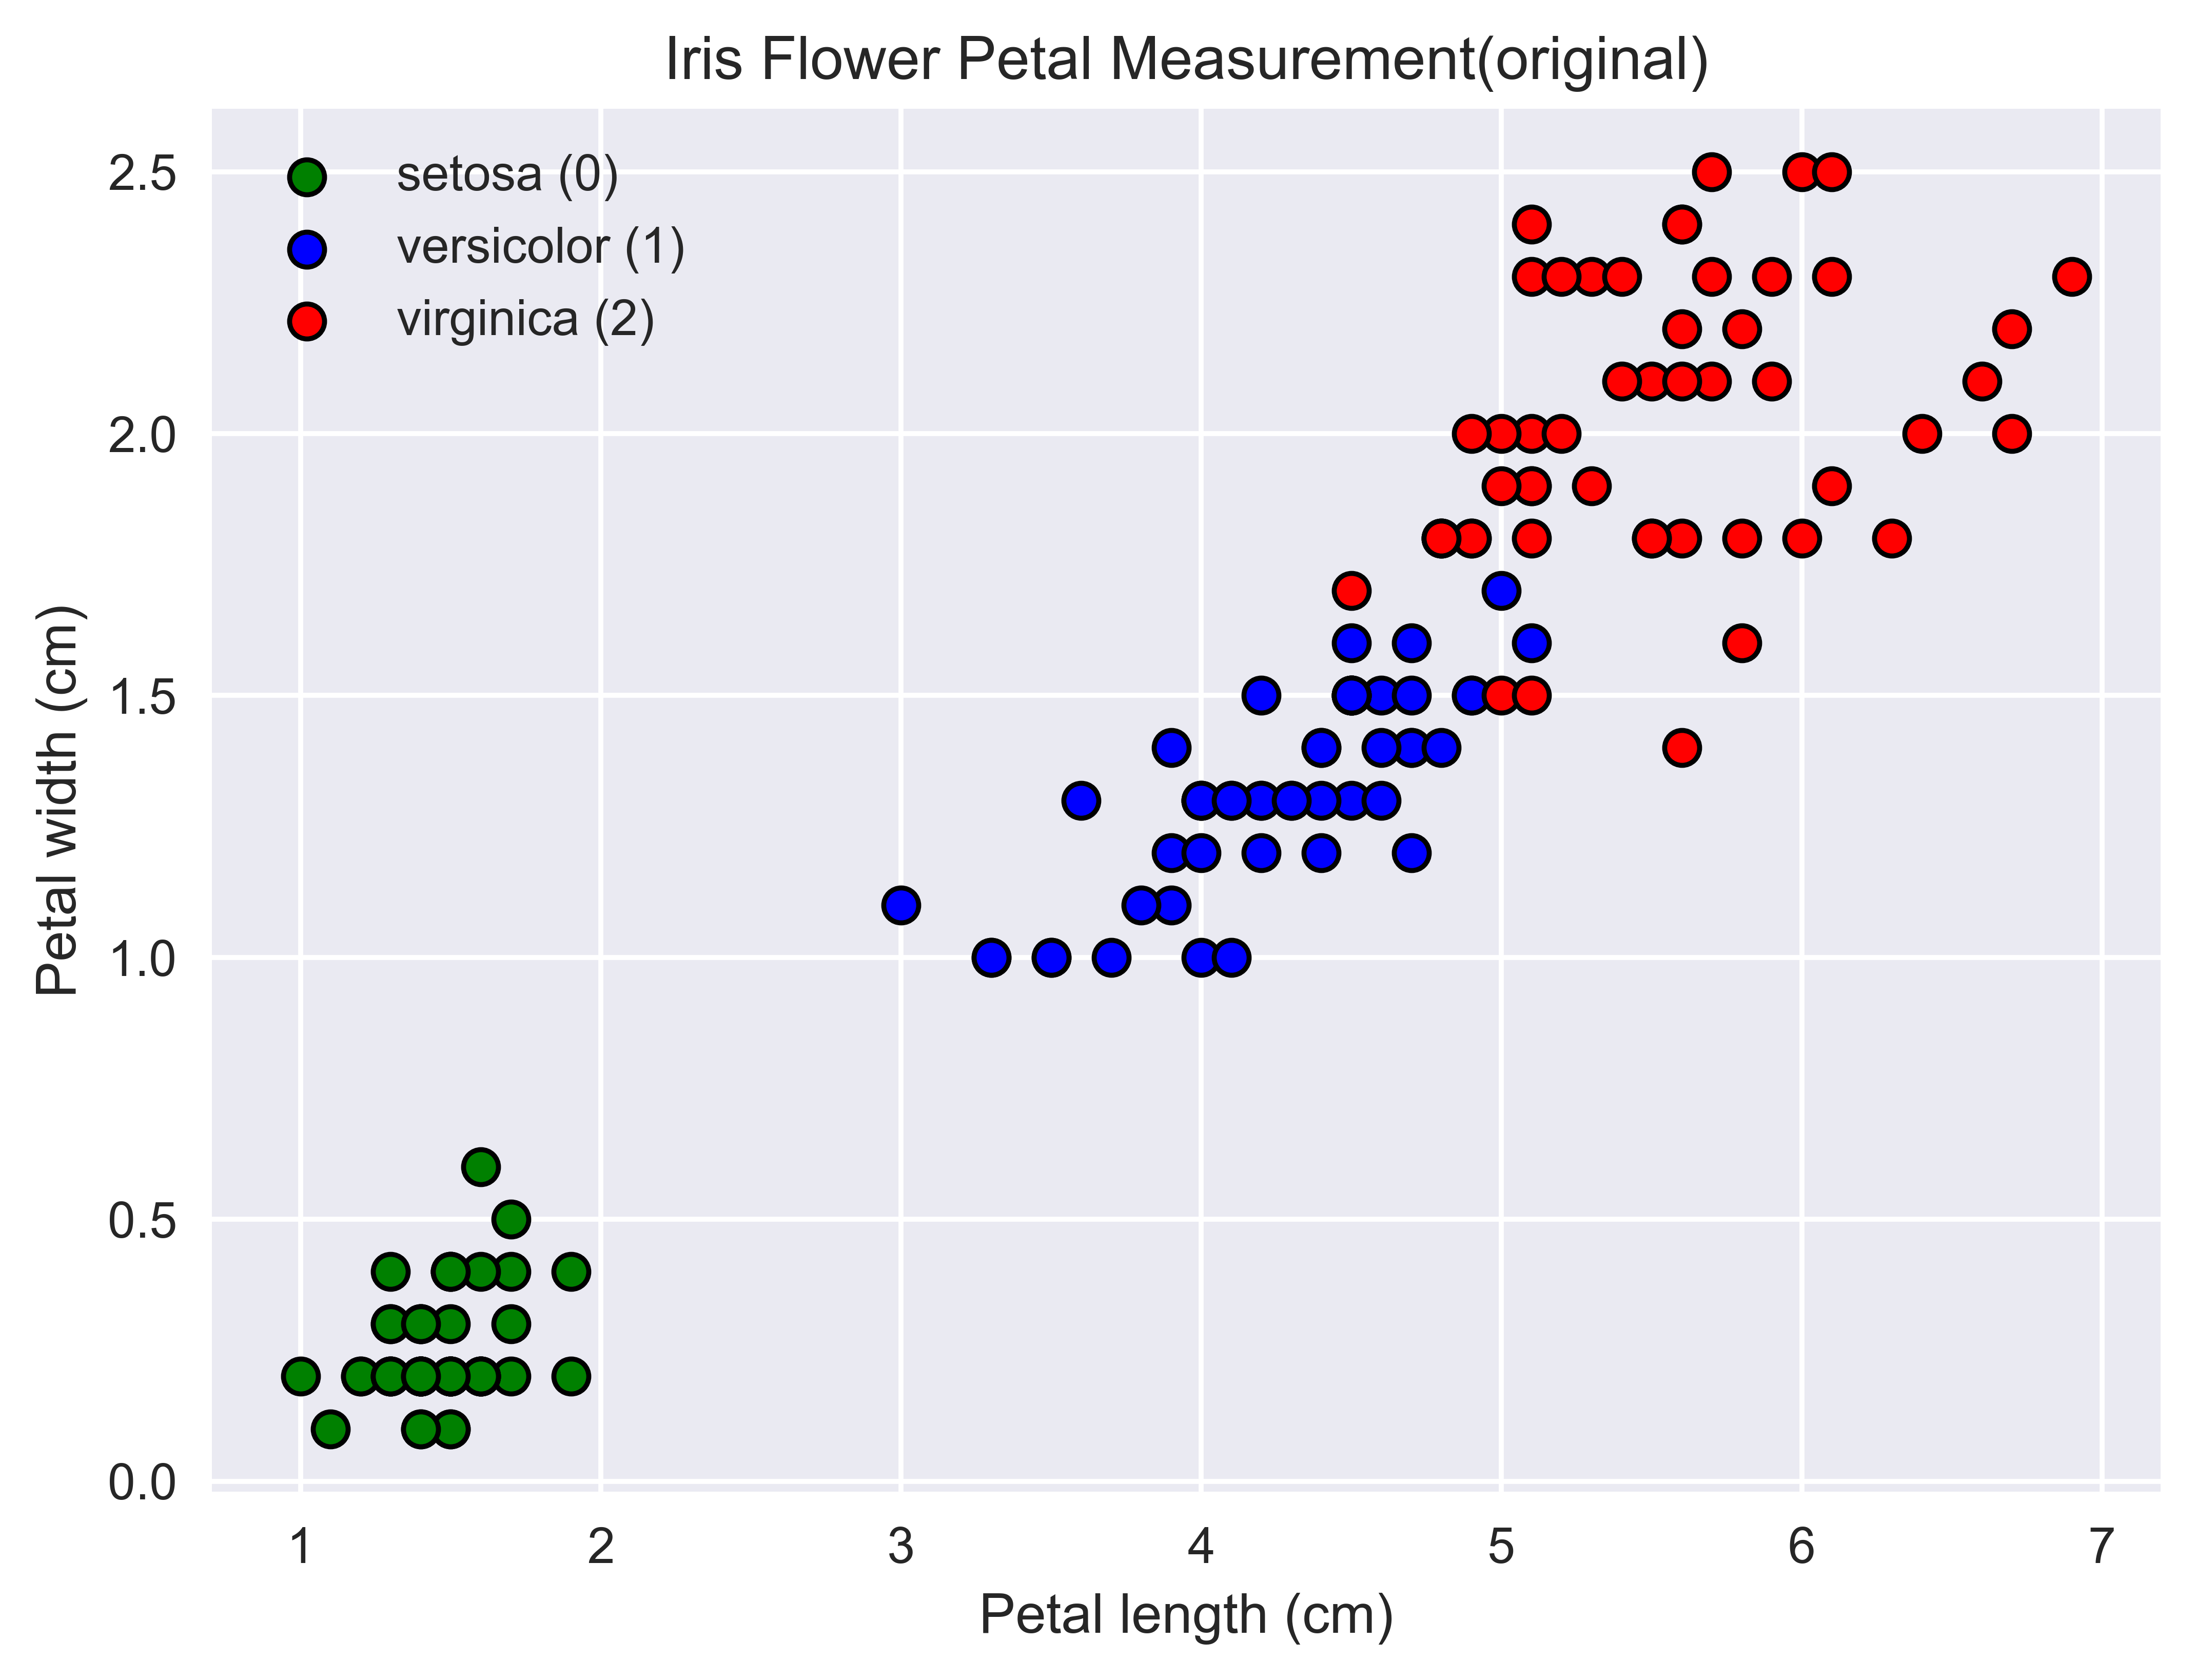

In [12]:
plt.figure(figsize=(7,5),dpi=700)
plt.style.use('seaborn')
plt.scatter(dfn0['petal length (cm)'],dfn0['petal width (cm)'],color='green',marker='o',edgecolor='black',linewidth=1,label='setosa (0)')
plt.scatter(dfn1['petal length (cm)'],dfn1['petal width (cm)'],color='blue',marker='o',edgecolor='black',linewidth=1,label='versicolor (1)')
plt.scatter(dfn2['petal length (cm)'],dfn2['petal width (cm)'],color='red',marker='o',edgecolor='black',linewidth=1,label='virginica (2)')
plt.legend()
plt.title('Iris Flower Petal Measurement(original)')
plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')

In [13]:
k_range = range(1,10)
sse  = []

for k in k_range:
    km = KMeans(n_clusters=k)
    km.fit(dfn[['petal length (cm)','petal width (cm)']])
    sse.append(km.inertia_)

In [14]:
sse

[28.368353219727197,
 5.176463590044368,
 1.701874688192097,
 1.1588792731667126,
 0.8538617353912241,
 0.6795297632254396,
 0.565127345570398,
 0.49377581806526427,
 0.41565361271607326]

Text(0, 0.5, 'SSE')

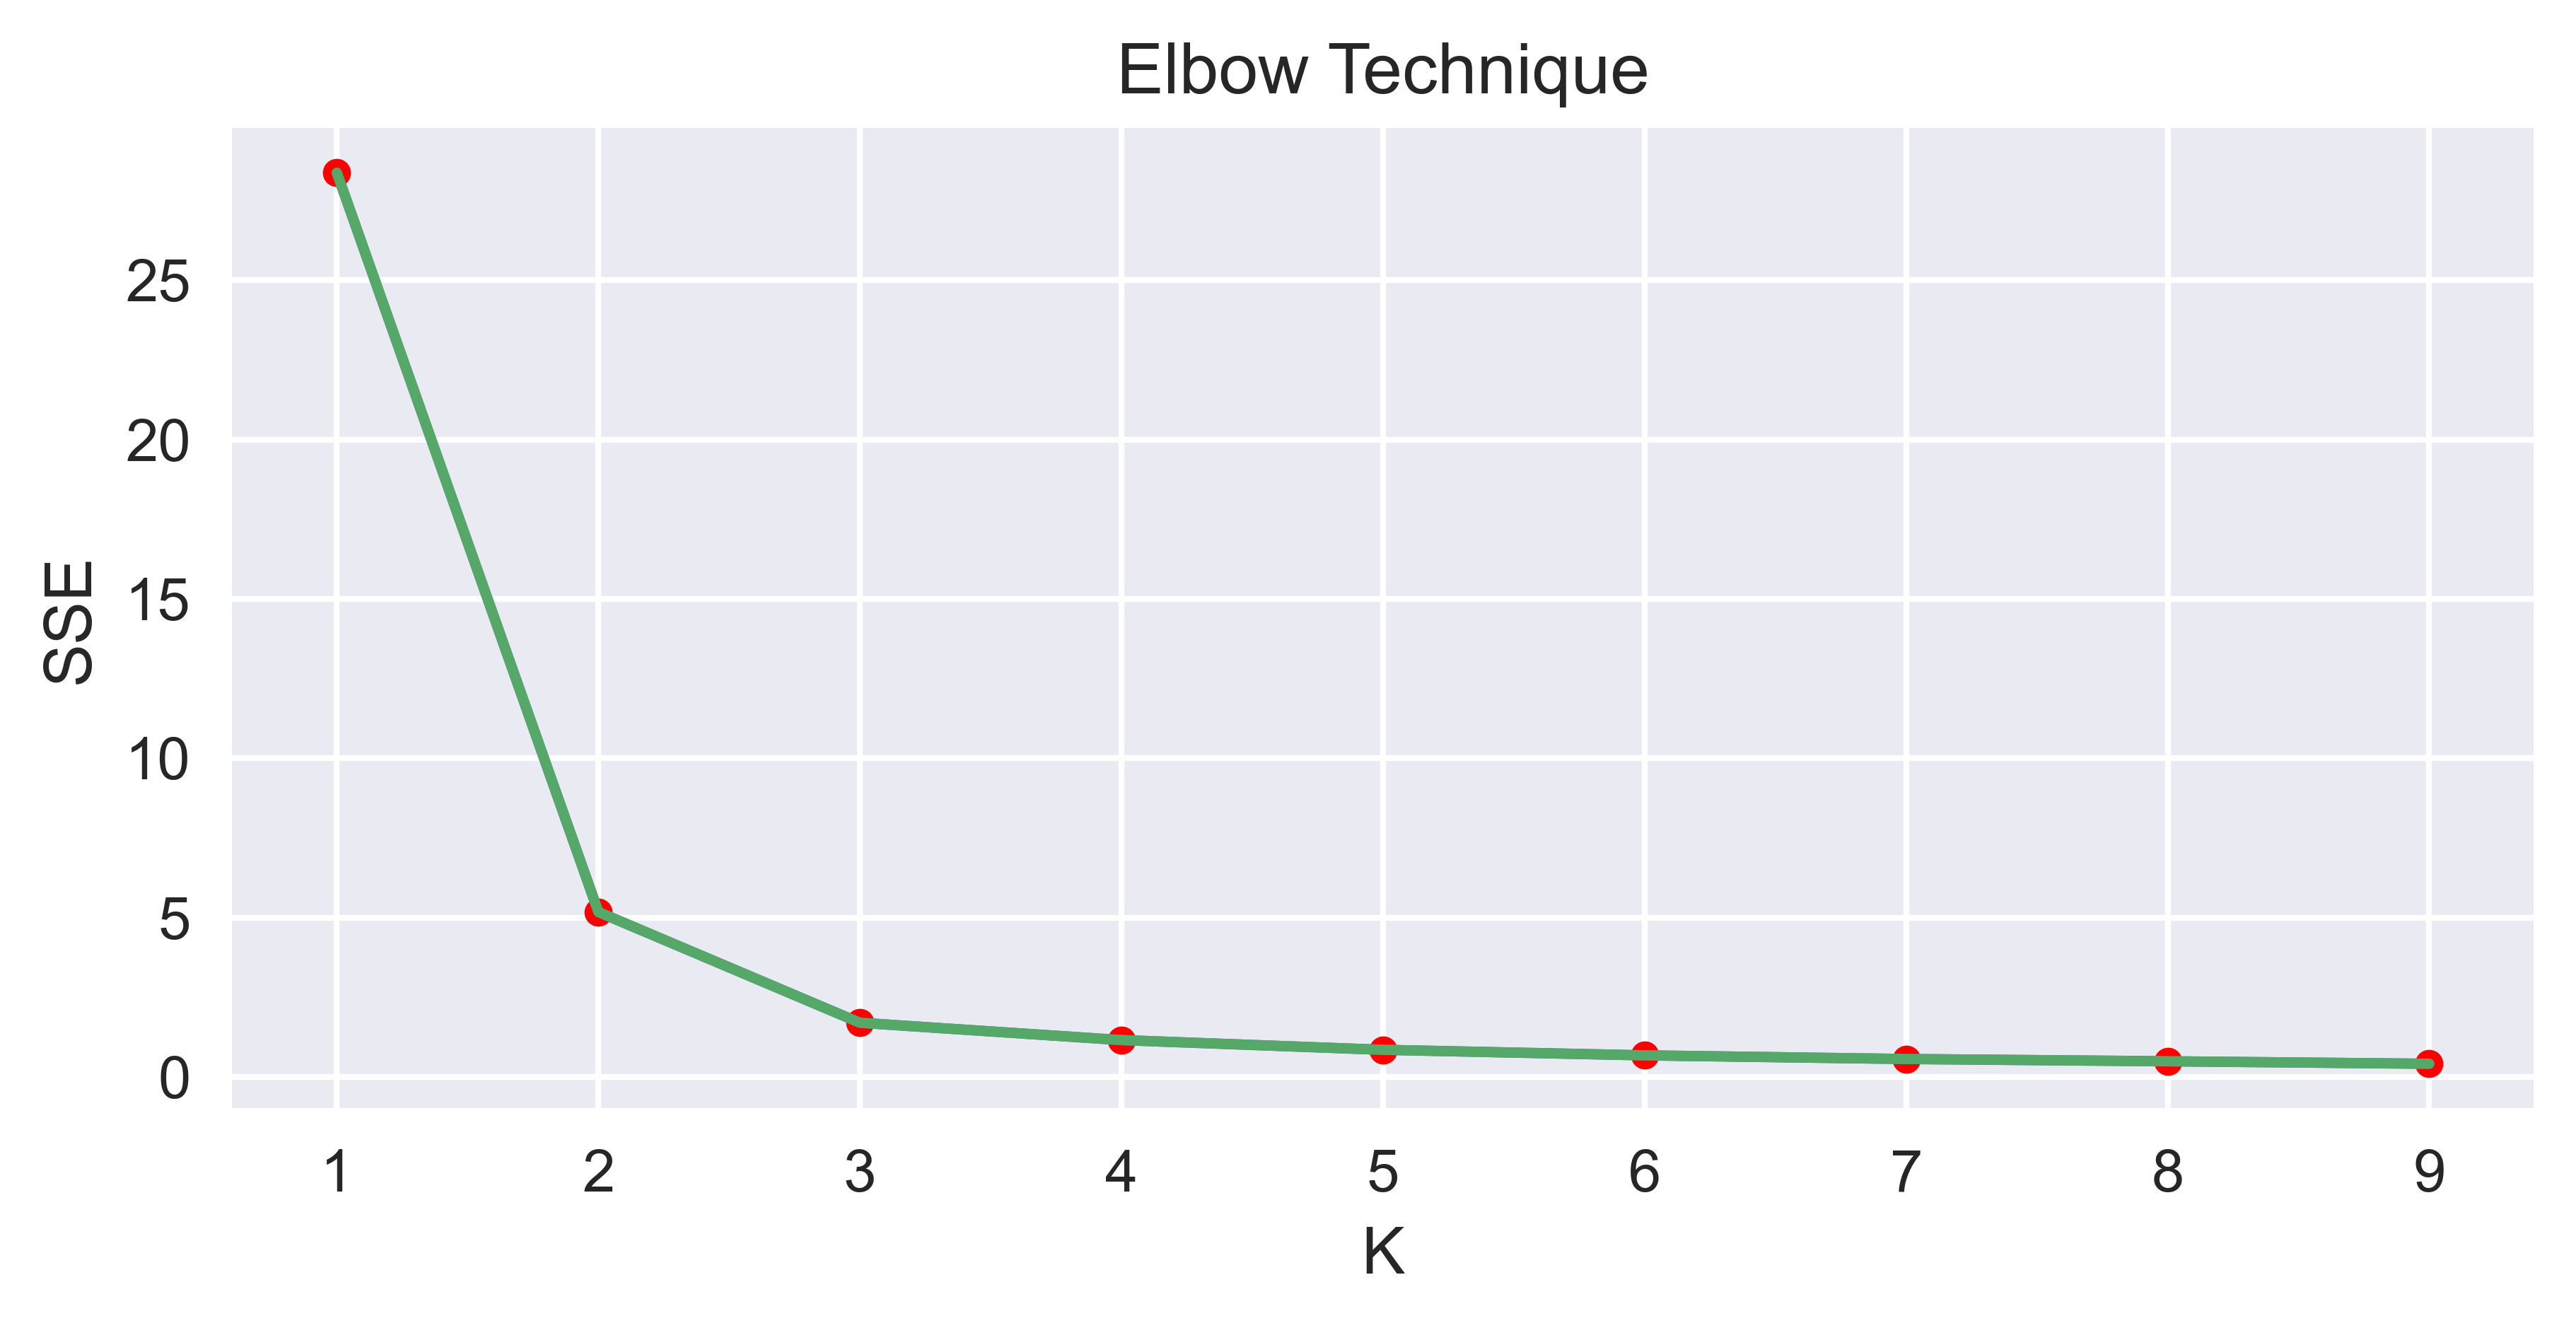

In [15]:
plt.figure(figsize=(7,3),dpi=600)
plt.plot(k_range,sse)
plt.scatter(k_range,sse,color='red',marker='o',s=20)
plt.plot(k_range,sse)
plt.title('Elbow Technique')
plt.xlabel('K')
plt.ylabel('SSE')

In [16]:
km = KMeans(n_clusters=3)
y_predicted = km.fit_predict(dfn[['petal length (cm)','petal width (cm)']])
y_predicted

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [17]:
dfn['Target_predicted']=y_predicted
dfn

,petal length (cm),petal width (cm),Target,Target_predicted
0,0.067797,0.041667,0,0
1,0.067797,0.041667,0,0
2,0.050847,0.041667,0,0
3,0.084746,0.041667,0,0
4,0.067797,0.041667,0,0
...,...,...,...,...
145,0.711864,0.916667,2,1
146,0.677966,0.750000,2,1
147,0.711864,0.791667,2,1
148,0.745763,0.916667,2,1


In [18]:
# df_predict0 = dfn[dfn.Target_predicted==0]
# df_predict1 = dfn[dfn.Target_predicted==1]
# df_predict2 = dfn[dfn.Target_predicted==2]



df_predict0 = dfn[dfn.Target_predicted==1]
df_predict1 = dfn[dfn.Target_predicted==2]
df_predict2 = dfn[dfn.Target_predicted==0]

Text(0, 0.5, 'Petal width (cm)')

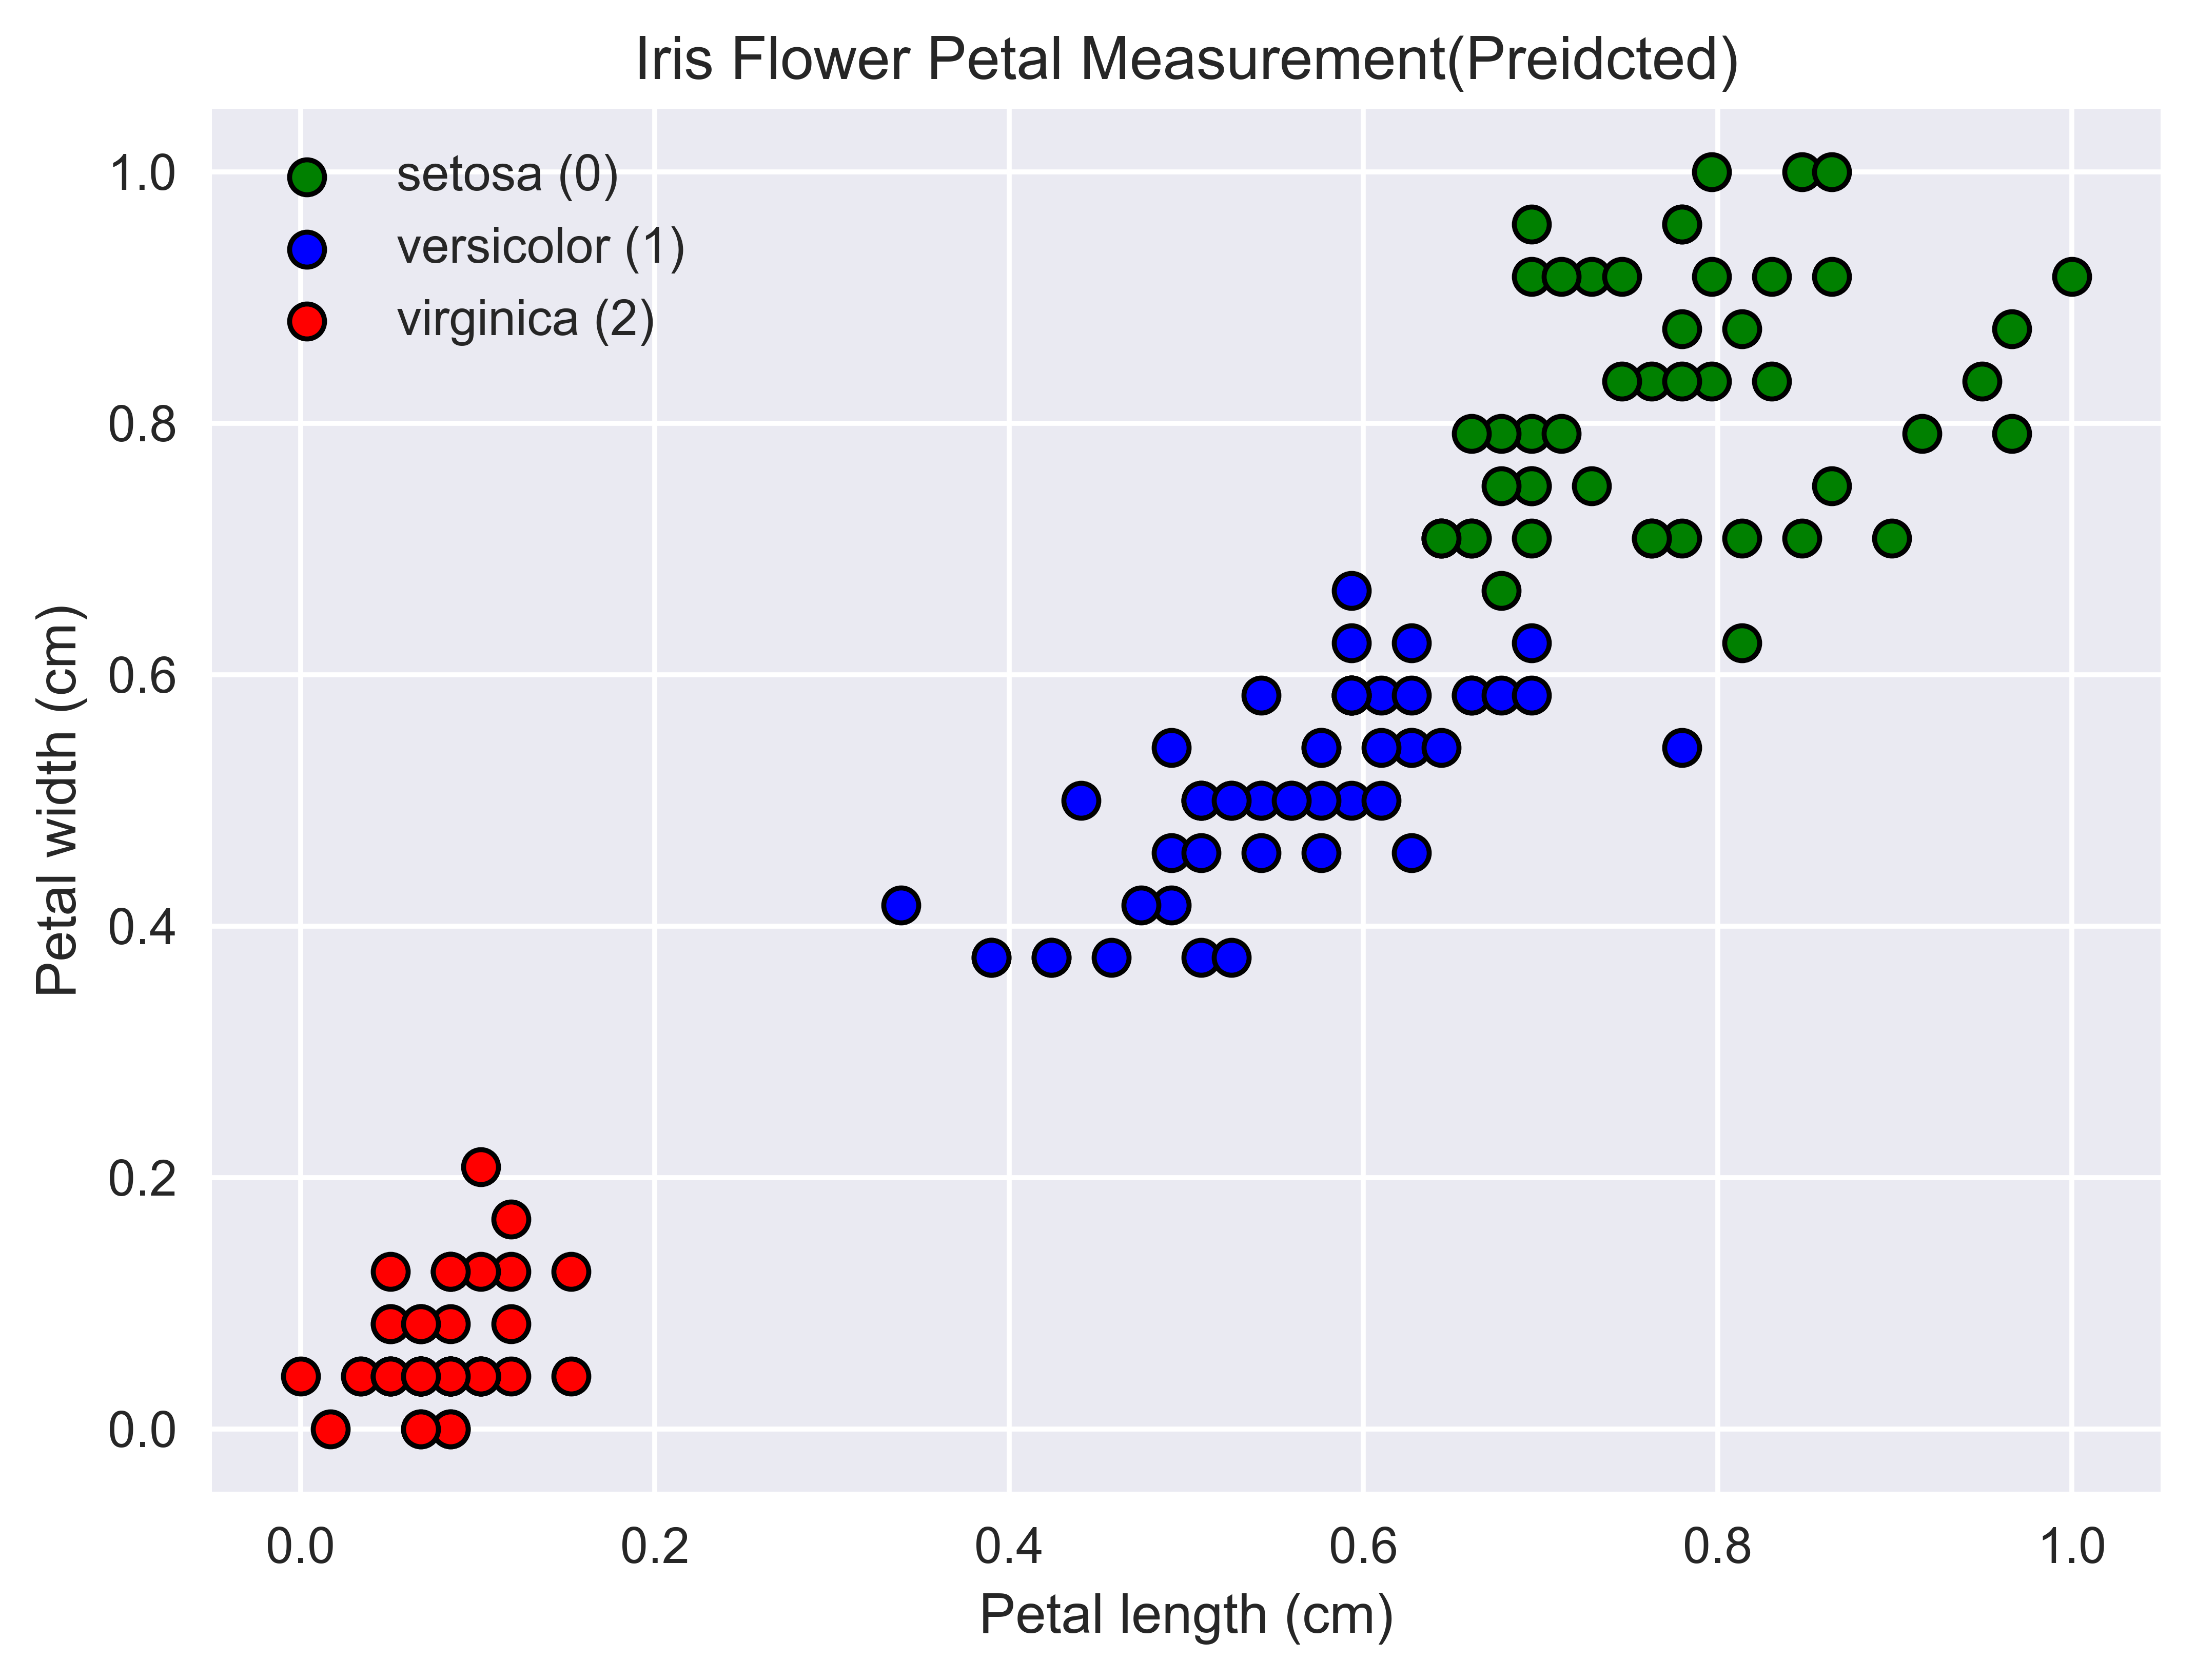

In [19]:
plt.figure(figsize=(7,5),dpi=700)
plt.style.use('seaborn')
plt.scatter(df_predict0['petal length (cm)'],df_predict0['petal width (cm)'],color='green',marker='o',edgecolor='black',linewidth=1,label='setosa (0)')
plt.scatter(df_predict1['petal length (cm)'],df_predict1['petal width (cm)'],color='blue',marker='o',edgecolor='black',linewidth=1,label='versicolor (1)')
plt.scatter(df_predict2['petal length (cm)'],df_predict2['petal width (cm)'],color='red',marker='o',edgecolor='black',linewidth=1,label='virginica (2)')
plt.legend()
plt.title('Iris Flower Petal Measurement(Preidcted)')
plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')

Text(0, 0.5, 'Petal width (cm)')

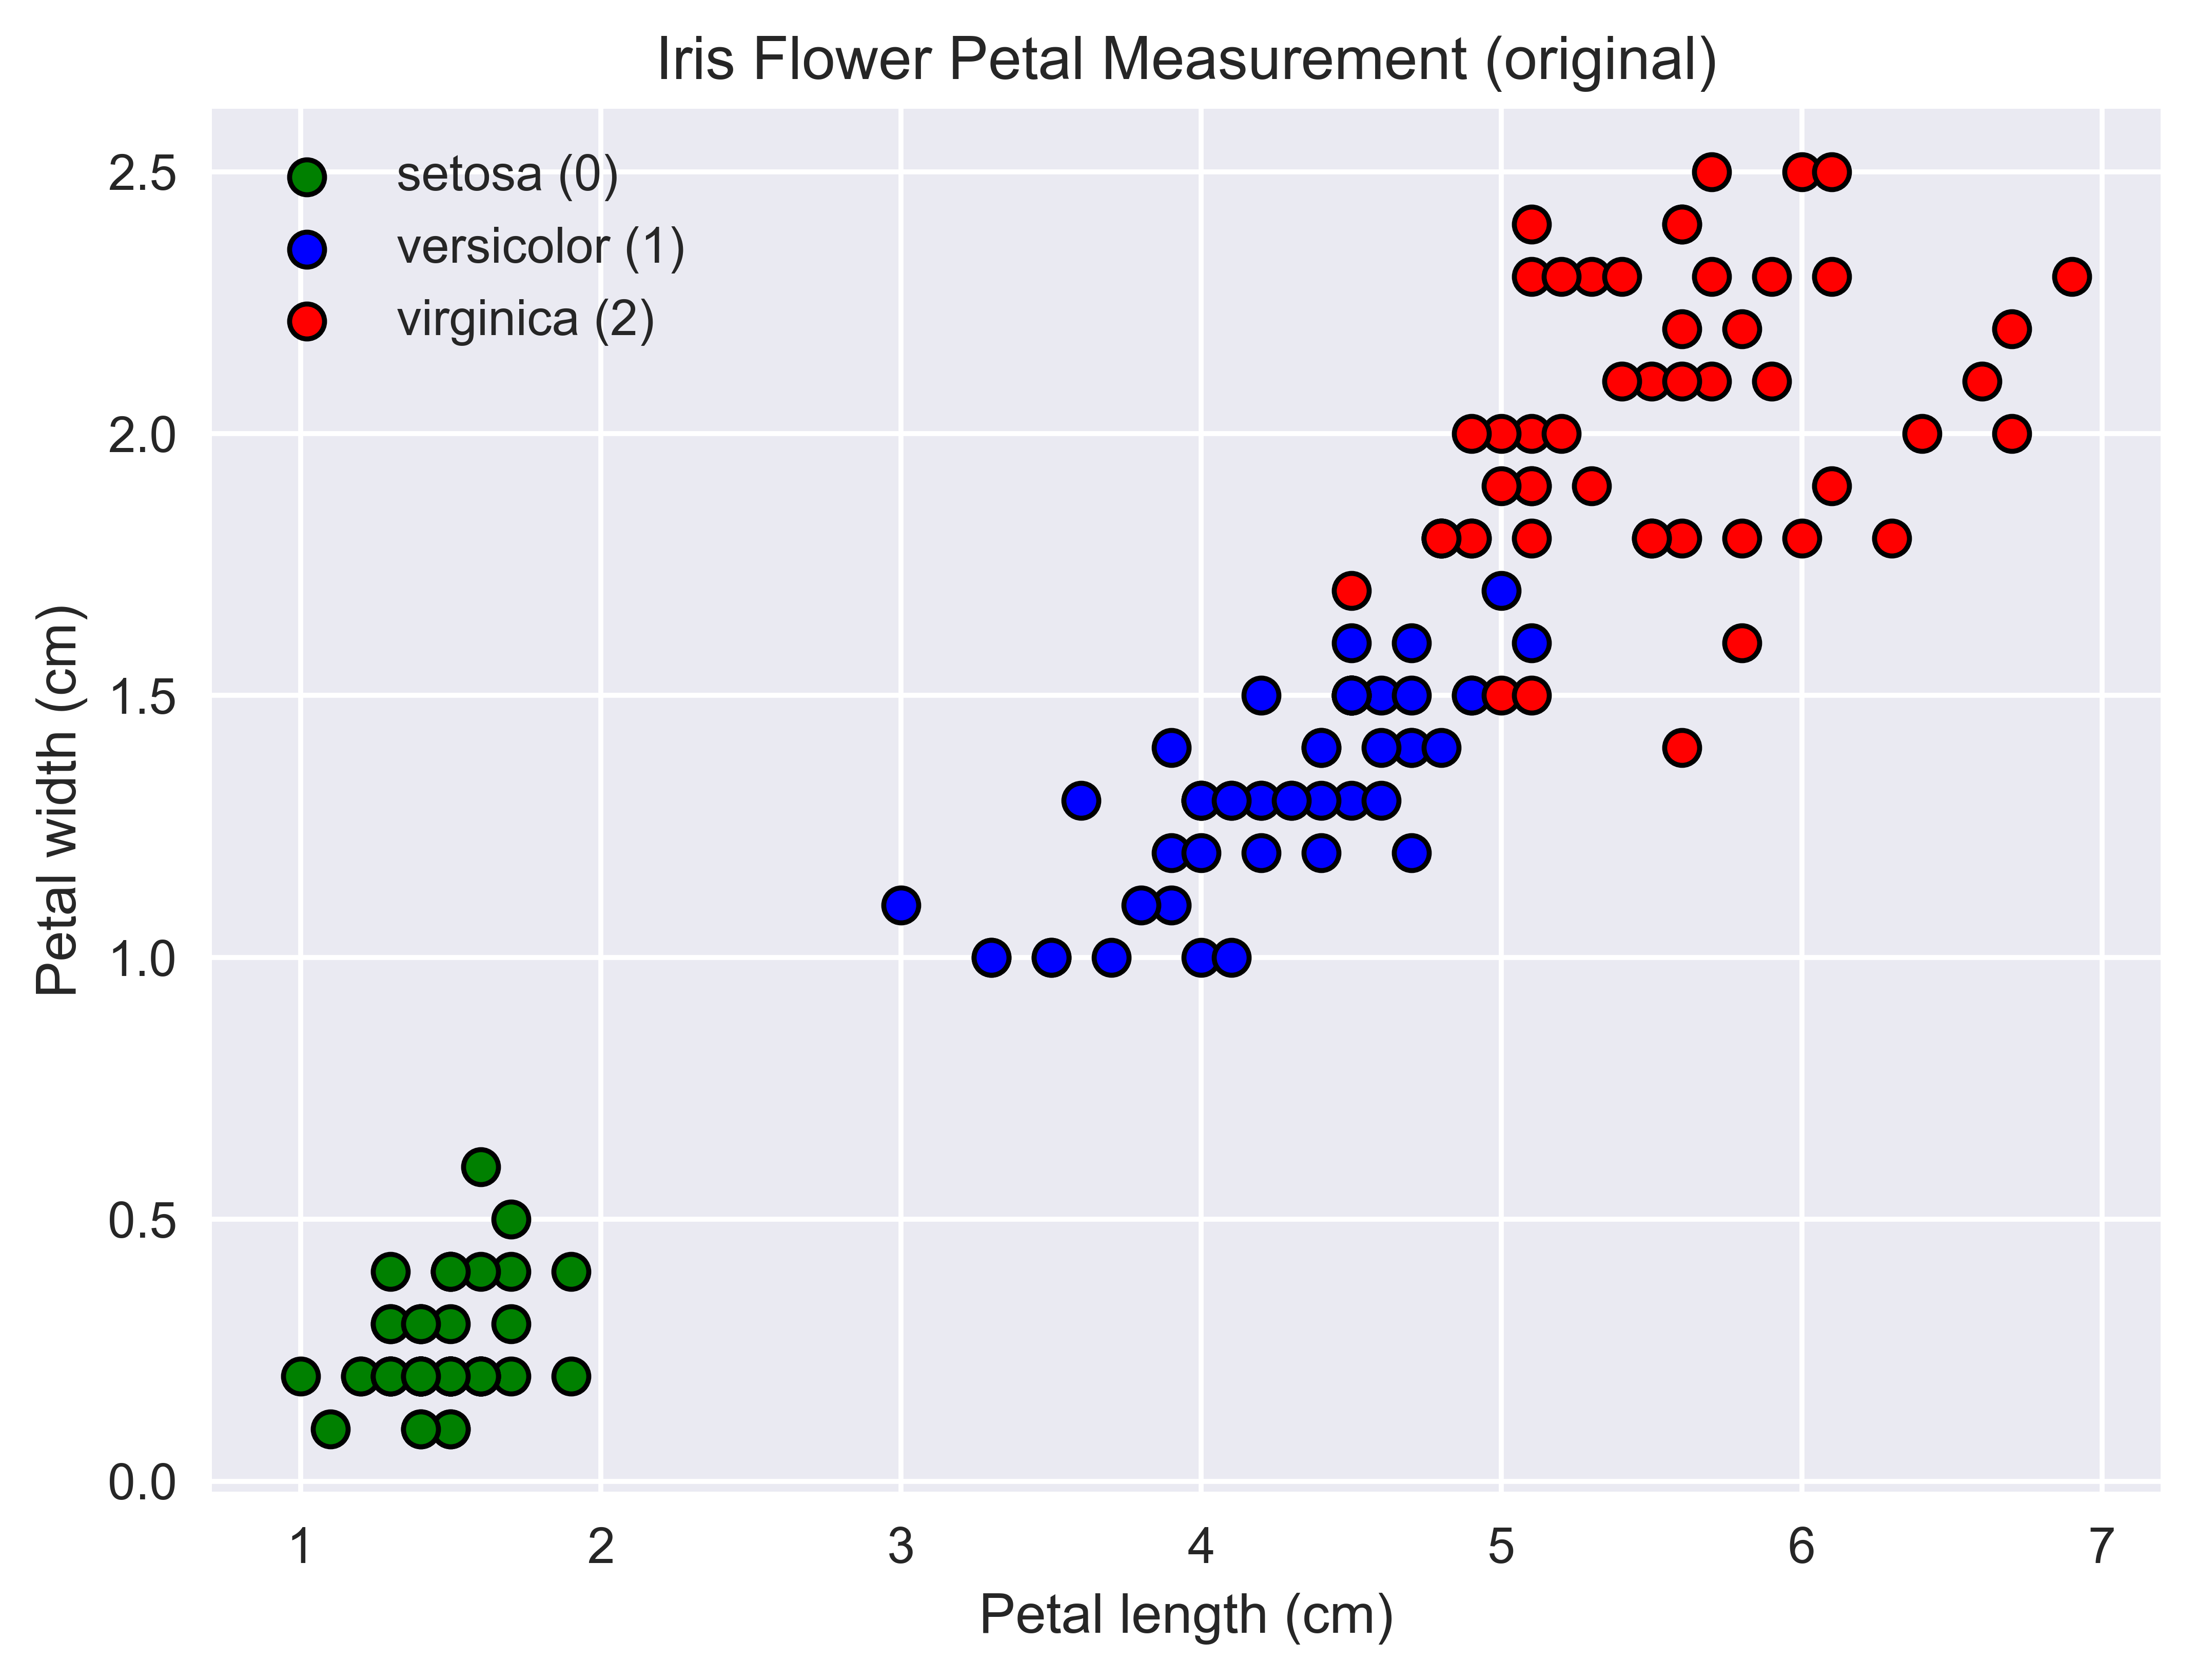

In [20]:
plt.figure(figsize=(7,5),dpi=700)
plt.style.use('seaborn')
plt.scatter(dfn0['petal length (cm)'],dfn0['petal width (cm)'],color='green',marker='o',edgecolor='black',linewidth=1,label='setosa (0)')
plt.scatter(dfn1['petal length (cm)'],dfn1['petal width (cm)'],color='blue',marker='o',edgecolor='black',linewidth=1,label='versicolor (1)')
plt.scatter(dfn2['petal length (cm)'],dfn2['petal width (cm)'],color='red',marker='o',edgecolor='black',linewidth=1,label='virginica (2)')
plt.legend()
plt.title('Iris Flower Petal Measurement (original)')
plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')

In [21]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [22]:
km.cluster_centers_

array([[0.07830508, 0.06083333],
       [0.7740113 , 0.81510417],
       [0.55867014, 0.51041667]])

Text(0, 0.5, 'Petal width (cm)')

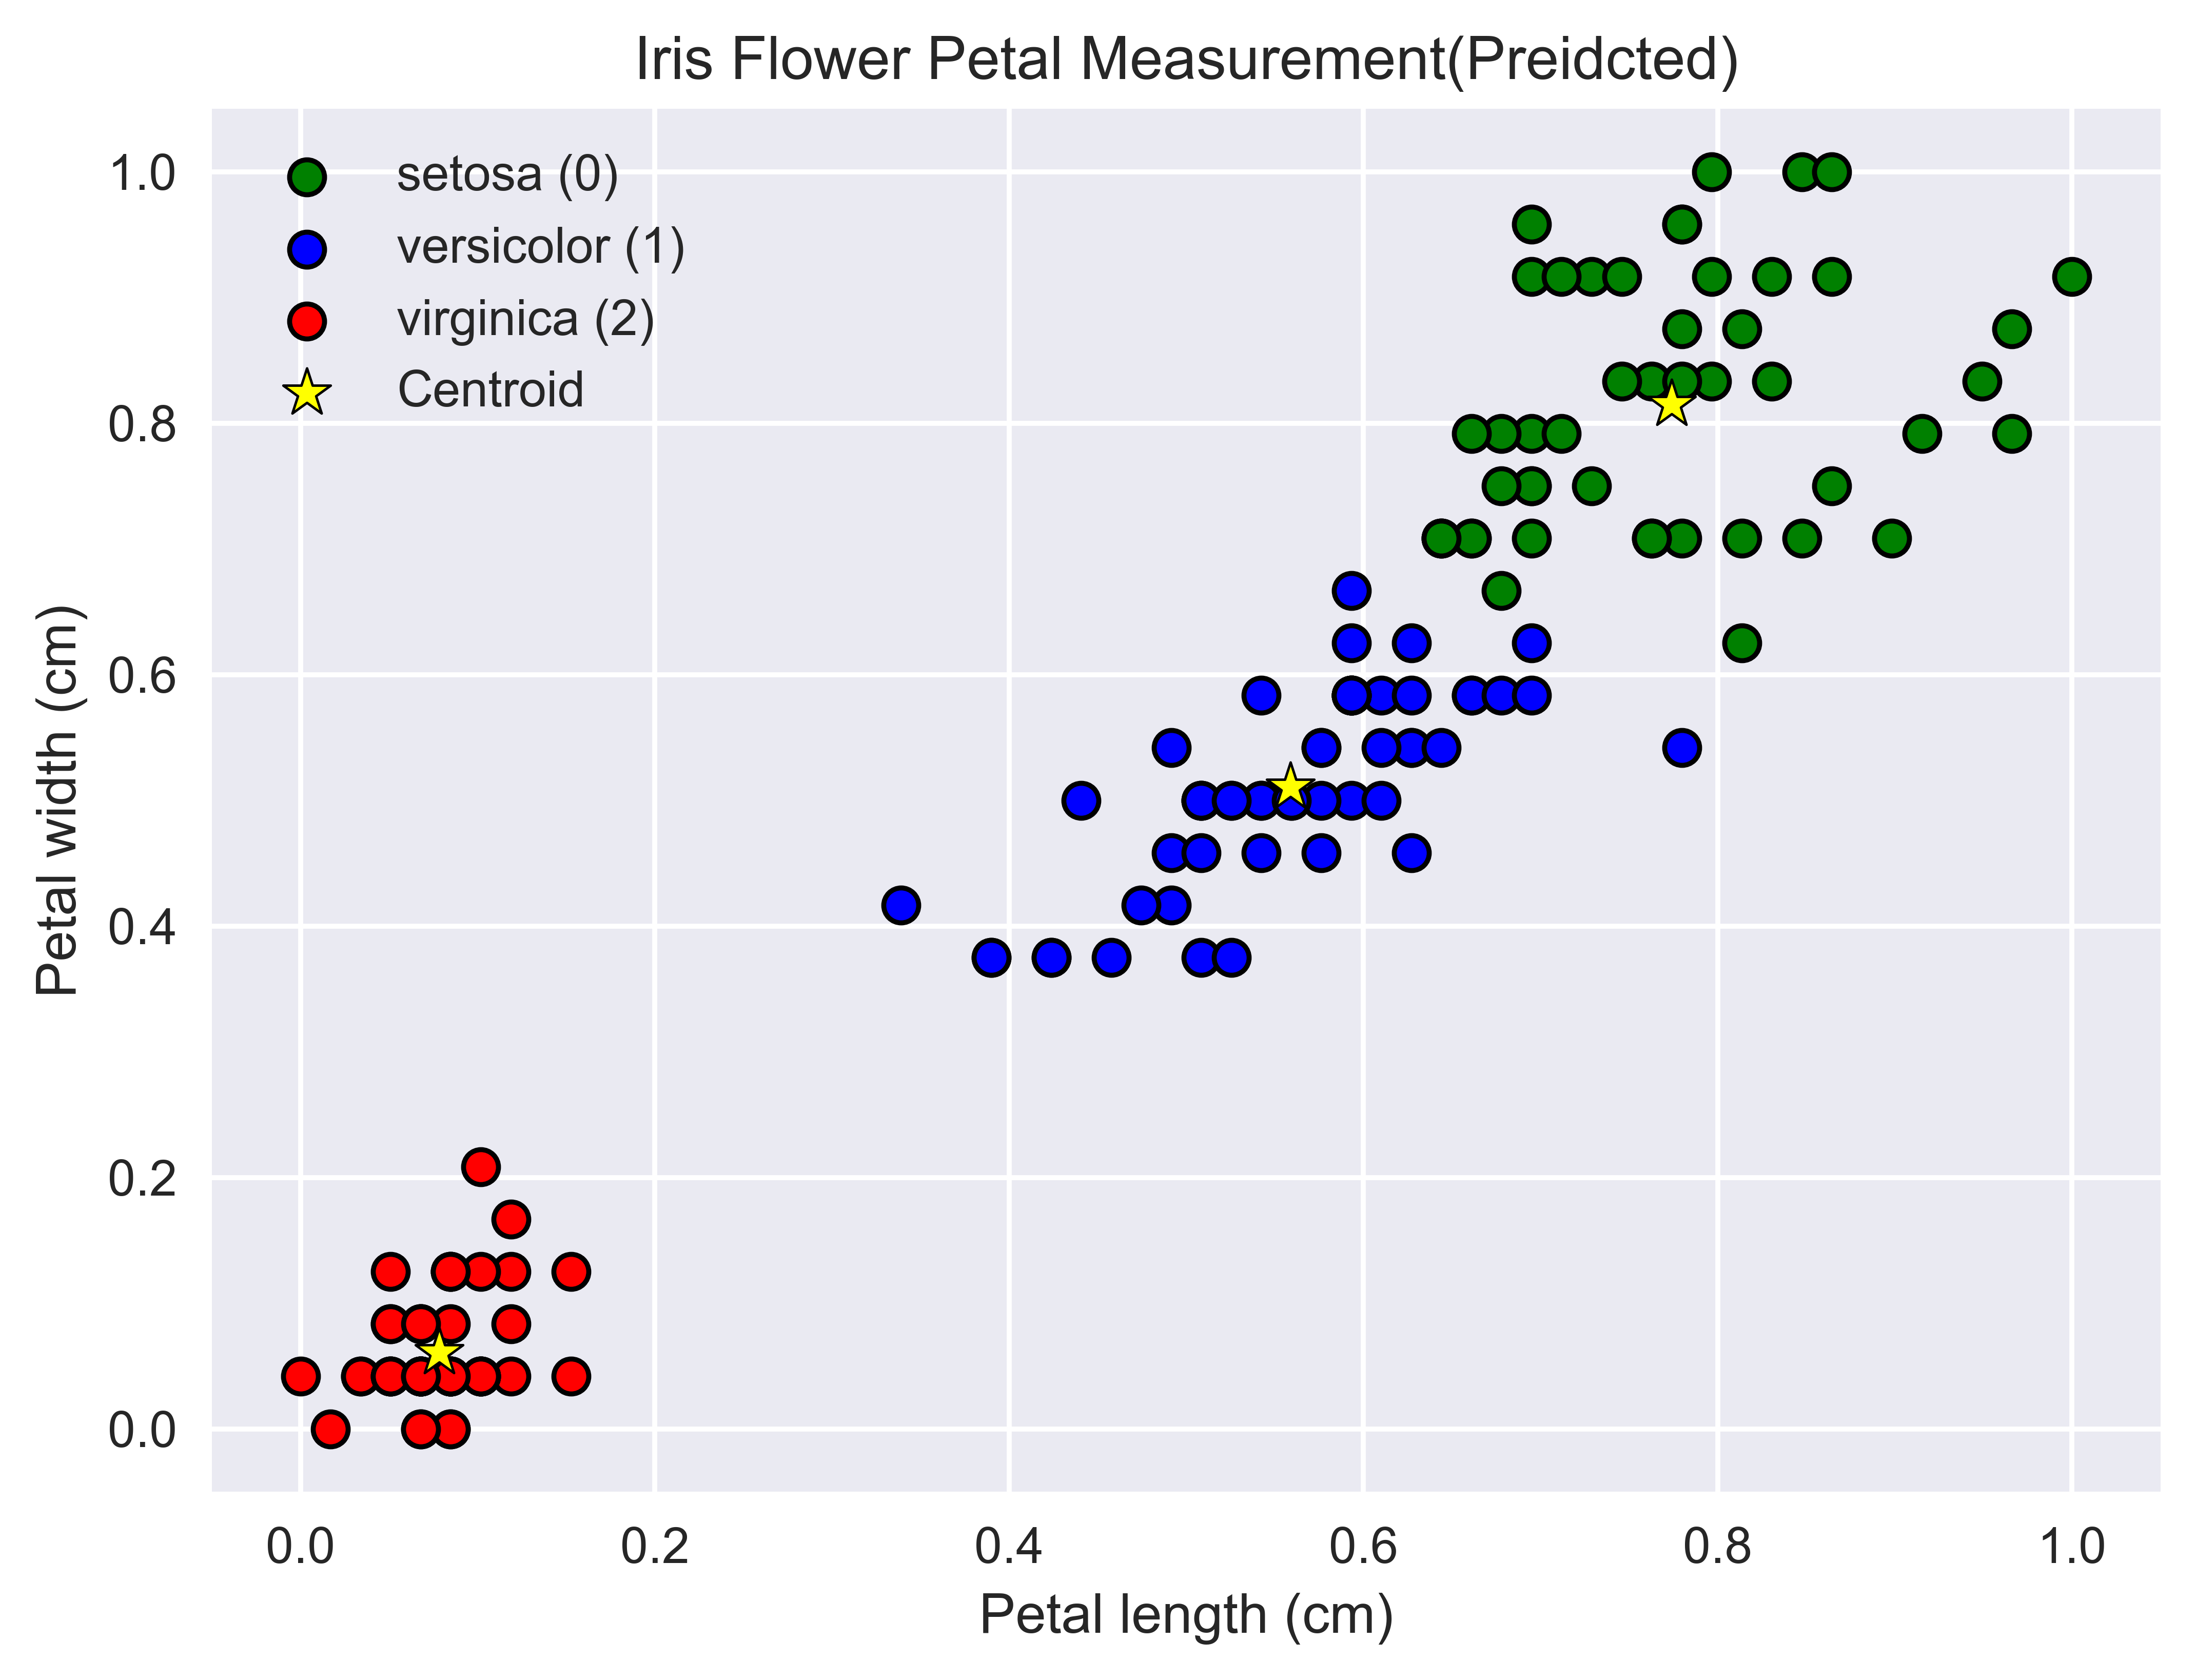

In [23]:
plt.figure(figsize=(7,5),dpi=700)
plt.style.use('seaborn')
plt.scatter(df_predict0['petal length (cm)'],df_predict0['petal width (cm)'],color='green',marker='o',edgecolor='black',linewidth=1,label='setosa (0)')
plt.scatter(df_predict1['petal length (cm)'],df_predict1['petal width (cm)'],color='blue',marker='o',edgecolor='black',linewidth=1,label='versicolor (1)')
plt.scatter(df_predict2['petal length (cm)'],df_predict2['petal width (cm)'],color='red',marker='o',edgecolor='black',linewidth=1,label='virginica (2)')

plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='yellow',marker='*',s=100,edgecolor='black',linewidth=0.5,label='Centroid')

plt.legend()
plt.title('Iris Flower Petal Measurement(Preidcted)')
plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')

## Sources

Source: [Codebasics](https://github.com/codebasics/py).